In [18]:
import os
import math
import cv2
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Ellipse, Polygon
from ultralytics import YOLO
from scipy.optimize import linear_sum_assignment
from PIL import Image


# ============================================================
# Parameters
# ============================================================

img = "IMG1"
pol = "VV"
run_name = "chips_run1"

tif_path = (
    f"atalaya_data/scenes_tiff/"
    f"S1D_IW_GRDH_1SDV_{img}_{pol}.tif"
)

training_run_path = "models/rbox_detector"

csv_path = (
    f"atalaya_data/ships_csv/"
    f"S1D_IW_GRDH_1SDV_{img}_BUQUES.csv"
)

# Output folder
output_folder = (
    f"atalaya_chip_dataset/{run_name}/{pol}"
)

# Detection parameters
conf = 0.3
iou = 0.7

# AIS matching radius
radius_km = 1.0

# Padding around the OBB, in pixels
chip_padding = 20

# Plot parameters
plot_with_padding = False


# ============================================================
# Create output folder
# ============================================================

os.makedirs(output_folder, exist_ok=True)


# ============================================================
# Load YOLO OBB model
# ============================================================

detector_model = YOLO(
    f"{training_run_path}/best.pt"
)


# ============================================================
# Load ships CSV
# ============================================================

df = pd.read_csv(csv_path)

ships = df.to_dict(orient="records")

csv_fields = list(df.columns)


# ============================================================
# Read GeoTIFF
# ============================================================

with rasterio.open(tif_path) as src:

    sar = src.read(1)

    bounds = src.bounds
    transform = src.transform
    crs = src.crs

print("Image shape:", sar.shape)
print("CRS:", crs)
print("Bounds:", bounds)


# ============================================================
# Normalize SAR image
# ============================================================

sar = 20 * np.log10(
    np.maximum(np.abs(sar), 1e-10)
)

sar_norm = (
    (sar - sar.min()) /
    (sar.max() - sar.min()) *
    255
).astype(np.uint8)

# Convert grayscale to RGB for YOLO
rgb = np.stack(
    [sar_norm, sar_norm, sar_norm],
    axis=-1
)


# ============================================================
# Run YOLO OBB detector
# ============================================================

results = detector_model.predict(
    source=rgb,
    conf=conf,
    iou=iou,
    save=False,
    show=False,
    verbose=False
)

result = results[0]

if result.obb is None:
    raise RuntimeError(
        "No OBB results returned. "
        "Check that the loaded model is an OBB model."
    )

obb = result.obb

print(f"\nYOLO detections: {len(obb)}")


# ============================================================
# Extract OBB detections
# ============================================================

detections = []

if len(obb) > 0:

    corners_array = (
        obb.xyxyxyxy.cpu().numpy()
    )

    confidences = obb.conf.cpu().numpy()

    classes = obb.cls.cpu().numpy().astype(int)

    for i in range(len(obb)):

        corners = corners_array[i]

        # Calculate ship aspect ratio
        edges = np.roll(corners, -1, axis=0) - corners
        
        edge_lengths = np.linalg.norm(edges, axis=1)
        
        length = np.max(edge_lengths)
        width = np.min(edge_lengths)
        
        aspect_ratio = (
            length / width if width > 0 else np.nan
        )

        # Center in pixel coordinates
        x_center = corners[:, 0].mean()
        y_center = corners[:, 1].mean()

        # Convert to geographic coordinates
        lon, lat = rasterio.transform.xy(
            transform,
            y_center,
            x_center
        )

        # Axis-aligned bounding box, for reference
        x1 = corners[:, 0].min()
        y1 = corners[:, 1].min()
        x2 = corners[:, 0].max()
        y2 = corners[:, 1].max()

        detections.append({

            "id": i,

            # Geographic center
            "lat": lat,
            "lon": lon,

            # Four OBB corners
            "corners": corners,

            # OBB dimensions and aspect ratio
            "length": length,
            "width": width,
            "aspect_ratio": aspect_ratio,

            # Pixel center
            "x_pixel": x_center,
            "y_pixel": y_center,

            # Axis-aligned bounding box
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2,

            # Confidence and class
            "confidence": float(confidences[i]),
            "class": int(classes[i])
        })


# ============================================================
# Find CSV ships inside image
# ============================================================

ships_inside = []

for ship in ships:

    lat = ship["lat"]
    lon = ship["lon"]

    if pd.isna(lat) or pd.isna(lon):
        continue

    if (
        bounds.left <= lon <= bounds.right
        and
        bounds.bottom <= lat <= bounds.top
    ):
        ships_inside.append(ship)


print(
    f"CSV ships inside image: {len(ships_inside)}"
)


# ============================================================
# Haversine distance
# ============================================================

def haversine_km(lat1, lon1, lat2, lon2):

    R = 6371.0

    lat1 = math.radians(lat1)
    lat2 = math.radians(lat2)

    dlat = lat2 - lat1
    dlon = math.radians(lon2 - lon1)

    a = (
        math.sin(dlat / 2) ** 2
        +
        math.cos(lat1)
        * math.cos(lat2)
        * math.sin(dlon / 2) ** 2
    )

    c = 2 * math.atan2(
        math.sqrt(a),
        math.sqrt(1 - a)
    )

    return R * c


# ============================================================
# Hungarian matching
# ============================================================

num_ships = len(ships_inside)
num_detections = len(detections)

print("\nPerforming Hungarian matching...")

matches = []

if num_ships > 0 and num_detections > 0:

    distance_matrix = np.zeros(
        (num_ships, num_detections)
    )

    for i, ship in enumerate(ships_inside):

        for j, detection in enumerate(detections):

            distance_matrix[i, j] = haversine_km(
                ship["lat"],
                ship["lon"],
                detection["lat"],
                detection["lon"]
            )

    unmatched_cost = radius_km + 0.001
    invalid_cost = unmatched_cost * 1000

    cost_matrix = distance_matrix.copy()

    cost_matrix[
        cost_matrix > radius_km
    ] = invalid_cost

    n = max(num_ships, num_detections)

    padded_cost = np.full(
        (n, n),
        unmatched_cost,
        dtype=float
    )

    padded_cost[
        :num_ships,
        :num_detections
    ] = cost_matrix

    row_ind, col_ind = linear_sum_assignment(
        padded_cost
    )

    for row, col in zip(row_ind, col_ind):

        if row >= num_ships:
            continue

        if col >= num_detections:
            continue

        distance = distance_matrix[row, col]

        if distance <= radius_km:

            matches.append({

                "ship_index": row,
                "detection_index": col,
                "distance_km": distance
            })


# ============================================================
# Create lookup dictionaries
# ============================================================

detection_matches = {}
ship_matches = {}

for match in matches:

    detection_index = match["detection_index"]
    ship_index = match["ship_index"]

    detection_matches[detection_index] = match
    ship_matches[ship_index] = match


print(f"Valid Hungarian matches: {len(matches)}")


# ============================================================
# Print matches
# ============================================================

print("\nMatches:")

for match in matches:

    ship = ships_inside[match["ship_index"]]

    detection = detections[
        match["detection_index"]
    ]

    print(
        f"D{detection['id']} <-> "
        f"{ship['name']} | "
        f"{match['distance_km']:.3f} km"
    )

Image shape: (662, 1343)
CRS: EPSG:4326
Bounds: BoundingBox(left=-57.91231, bottom=-34.78219, right=-57.76702, top=-34.71054)

YOLO detections: 24
CSV ships inside image: 21

Performing Hungarian matching...
Valid Hungarian matches: 21

Matches:
D14 <-> VALDIVIA STAR | 0.637 km
D13 <-> AYANE | 0.348 km
D12 <-> CL MARGUERITE DURAS | 0.483 km
D21 <-> GRAND CHOICE | 0.215 km
D19 <-> MARIA EMILIA LV | 0.519 km
D15 <-> KOUSHUN | 0.383 km
D22 <-> LOYALTY | 0.374 km
D5 <-> ESTEFANIA H | 0.276 km
D3 <-> SILVER MUNA | 0.551 km
D7 <-> TAC IMOLA | 0.604 km
D20 <-> MORHOLMEN | 0.589 km
D17 <-> PUNTA MEDANOS | 0.528 km
D9 <-> EDUARDO V | 0.388 km
D2 <-> MSC AVNI | 0.470 km
D4 <-> MEGHNA VICTORY | 0.335 km
D6 <-> BELYAMATO | 0.468 km
D0 <-> AFRICAN CARDINAL | 0.584 km
D1 <-> ZJ ATLANTIC | 0.472 km
D11 <-> MRC SEDEF | 0.653 km
D16 <-> PALENA STAR | 0.663 km
D8 <-> GRANDE SAN PAOLO | 0.190 km


Plot detections

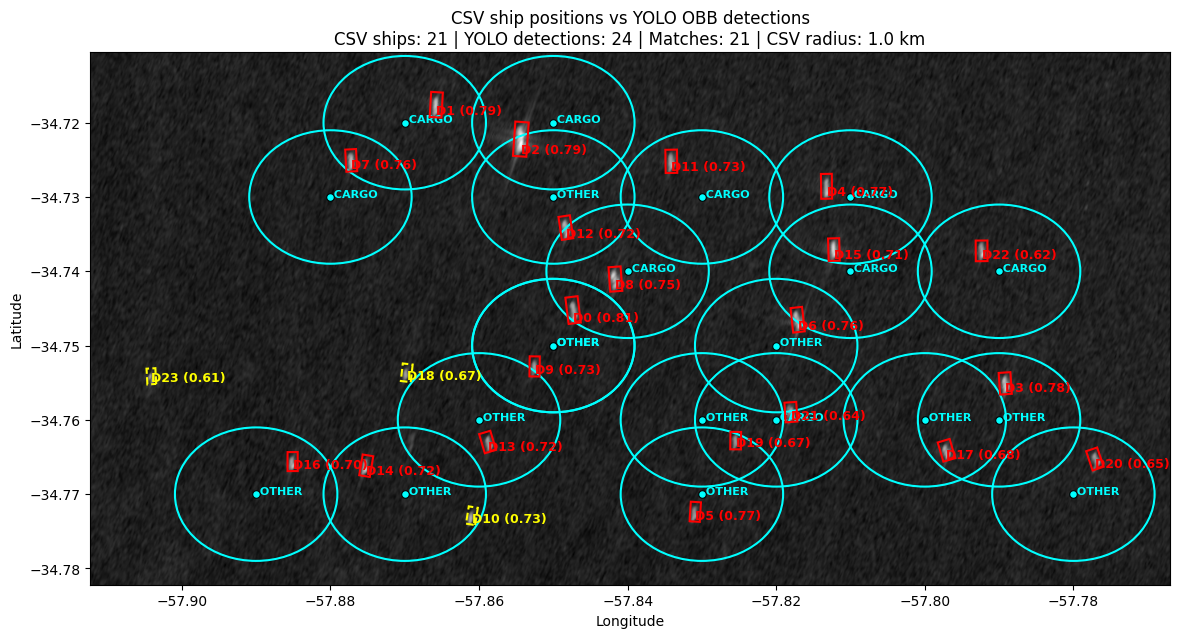

In [19]:

# ============================================================
# Convert uncertainty radius from km to degrees
# ============================================================

center_lat = (
    bounds.top + bounds.bottom
) / 2

km_per_degree_lat = 111.32

km_per_degree_lon = (
    111.32 *
    math.cos(math.radians(center_lat))
)

radius_lat = radius_km / km_per_degree_lat
radius_lon = radius_km / km_per_degree_lon


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(12, 7))

ax.imshow(
    sar,
    cmap="gray",
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper"
)


# ============================================================
# Plot CSV positions
# ============================================================

for ship in ships_inside:

    lon = ship["lon"]
    lat = ship["lat"]

    ax.scatter(
        lon,
        lat,
        marker="o",
        s=30,
        color="cyan",
        edgecolors="black",
        linewidths=0.8,
        zorder=4
    )

    ellipse = Ellipse(
        (lon, lat),
        width=2 * radius_lon,
        height=2 * radius_lat,
        fill=False,
        edgecolor="cyan",
        linewidth=1.5,
        zorder=3
    )

    ax.add_patch(ellipse)

    ax.text(
        lon,
        lat,
        f" {ship['geartype']}",
        color="cyan",
        fontsize=8,
        fontweight="bold",
        zorder=5
    )


# ============================================================
# Plot OBB detections
# ============================================================

image_height, image_width = sar_norm.shape

for detection in detections:

    corners = detection["corners"].copy()

    # Optional approximate padding for visualization
    if plot_with_padding:

        center = corners.mean(axis=0)

        vectors = corners - center

        mean_radius = np.mean(
            np.linalg.norm(vectors, axis=1)
        )

        scale = (
            1 + chip_padding /
            max(mean_radius, 1e-6)
        )

        corners = center + vectors * scale

    # Convert pixel coordinates to geographic coordinates
    geographic_corners = []

    for x, y in corners:

        lon, lat = rasterio.transform.xy(
            transform,
            y,
            x
        )

        geographic_corners.append(
            [lon, lat]
        )

    geographic_corners = np.array(
        geographic_corners
    )

    if detection["id"] in detection_matches:

        edgecolor = "red"
        linestyle = "-"

    else:

        edgecolor = "yellow"
        linestyle = "--"

    polygon = Polygon(
        geographic_corners,
        closed=True,
        fill=False,
        edgecolor=edgecolor,
        linewidth=1.5,
        linestyle=linestyle,
        zorder=6
    )

    ax.add_patch(polygon)

    label_lon = geographic_corners[:, 0].mean()
    label_lat = geographic_corners[:, 1].min()

    ax.text(
        label_lon,
        label_lat,
        f"D{detection['id']} "
        f"({detection['confidence']:.2f})",
        color=edgecolor,
        fontsize=9,
        fontweight="bold",
        verticalalignment="bottom",
        zorder=7
    )


# ============================================================
# Plot formatting
# ============================================================

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.set_title(
    f"CSV ship positions vs YOLO OBB detections\n"
    f"CSV ships: {len(ships_inside)} | "
    f"YOLO detections: {len(detections)} | "
    f"Matches: {len(matches)} | "
    f"CSV radius: {radius_km} km"
)

plt.tight_layout()
plt.show()

Extract chips and features

In [20]:
# ============================================================
# Function: Create de-rotated square chip
# ============================================================

def extract_rotated_chip(
    image,
    corners,
    padding=20
):
    """
    Extract a square chip centered on an OBB.

    The longest edge of the OBB is aligned
    horizontally in the resulting chip.

    Parameters
    ----------
    image : numpy array
        Normalized grayscale SAR image.

    corners : numpy array
        Four OBB corners, shape (4, 2).

    padding : int
        Additional pixels on each side.

    Returns
    -------
    chip : numpy array
        Square, de-rotated image chip.

    chip_size : int
        Side length of the extracted chip.
    """

    corners = np.asarray(
        corners,
        dtype=np.float32
    )

    # --------------------------------------------------------
    # Calculate center
    # --------------------------------------------------------

    center = corners.mean(axis=0)

    cx, cy = center

    # --------------------------------------------------------
    # Calculate all four edge vectors
    # --------------------------------------------------------

    edges = np.roll(
        corners,
        -1,
        axis=0
    ) - corners

    edge_lengths = np.linalg.norm(
        edges,
        axis=1
    )

    # Find longest edge
    longest_edge_idx = np.argmax(
        edge_lengths
    )

    longest_edge = edges[
        longest_edge_idx
    ]

    # --------------------------------------------------------
    # Calculate orientation
    # --------------------------------------------------------

    angle_rad = math.atan2(
        longest_edge[1],
        longest_edge[0]
    )

    angle_deg = math.degrees(
        angle_rad
    )

    # --------------------------------------------------------
    # Calculate square chip size
    # --------------------------------------------------------

    max_dimension = np.max(
        edge_lengths
    )

    chip_size = int(
        math.ceil(max_dimension + 2 * padding)
    )

    # Ensure minimum size
    chip_size = max(chip_size, 1)

    # --------------------------------------------------------
    # Create rotation matrix
    # --------------------------------------------------------

    M = cv2.getRotationMatrix2D(
        (float(cx), float(cy)),
        angle_deg,
        1.0
    )

    # --------------------------------------------------------
    # Translate ship center to chip center
    # --------------------------------------------------------

    M[0, 2] += chip_size / 2 - cx
    M[1, 2] += chip_size / 2 - cy

    # --------------------------------------------------------
    # Rotate and extract square chip directly
    # --------------------------------------------------------

    chip = cv2.warpAffine(
        image,
        M,
        (chip_size, chip_size),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    return chip, chip_size


# ============================================================
# Extract and save chips
# ============================================================

print("\nSaving de-rotated square chips...")

metadata_rows = []

for detection in detections:

    detection_id = detection["id"]

    corners = detection["corners"]

    # --------------------------------------------------------
    # Extract square, de-rotated chip
    # --------------------------------------------------------

    chip, chip_size = extract_rotated_chip(
        sar_norm,
        corners,
        padding=chip_padding
    )

    # --------------------------------------------------------
    # Save chip
    # --------------------------------------------------------

    chip_filename = f"D{detection_id}.png"

    chip_path = os.path.join(
        output_folder,
        chip_filename
    )

    Image.fromarray(chip).save(
        chip_path
    )

    # --------------------------------------------------------
    # Calculate original OBB coordinates
    # --------------------------------------------------------

    x1 = corners[:, 0].min()
    y1 = corners[:, 1].min()
    x2 = corners[:, 0].max()
    y2 = corners[:, 1].max()

    # --------------------------------------------------------
    # Start metadata row
    # --------------------------------------------------------

    row = {
        field: None
        for field in csv_fields
    }

    row[f"detection_id_{pol.lower()}"] = detection_id

    row["chip_filename"] = chip_filename

    row["detection_lat"] = detection["lat"]
    row["detection_lon"] = detection["lon"]

    row["confidence"] = detection["confidence"]

    # Aspect ratio features
    row["ship_length_pixels"] = detection["length"]
    row["ship_width_pixels"] = detection["width"]
    row["length_width_ratio"] = detection["aspect_ratio"]

    # Axis-aligned bbox enclosing the OBB
    row["bbox_x1"] = x1
    row["bbox_y1"] = y1
    row["bbox_x2"] = x2
    row["bbox_y2"] = y2

    # Chip information
    row["chip_size"] = chip_size
    row["chip_x1"] = detection["x_pixel"] - chip_size / 2
    row["chip_y1"] = detection["y_pixel"] - chip_size / 2
    row["chip_x2"] = detection["x_pixel"] + chip_size / 2
    row["chip_y2"] = detection["y_pixel"] + chip_size / 2

    # Store OBB corners as well
    for i, (x, y) in enumerate(corners):

        row[f"obb_x{i+1}"] = x
        row[f"obb_y{i+1}"] = y

    # --------------------------------------------------------
    # Hungarian matching
    # --------------------------------------------------------

    if detection_id in detection_matches:

        match = detection_matches[detection_id]

        ship = ships_inside[
            match["ship_index"]
        ]

        for field in csv_fields:
            row[field] = ship[field]

        row["matching_distance_km"] = (
            match["distance_km"]
        )

        row["matched"] = True

    else:

        row["matching_distance_km"] = None
        row["matched"] = False

    metadata_rows.append(row)


# ============================================================
# Save metadata CSV
# ============================================================

metadata_df = pd.DataFrame(
    metadata_rows
)

# Preserve original output columns
metadata_df = metadata_df[
    [
        f"detection_id_{pol.lower()}",
        "callsign",
        "geartype",
        "ship_length_pixels",
        "ship_width_pixels",
        "length_width_ratio"
    ]
]

metadata_csv_path = os.path.join(
    output_folder,
    f"chip_metadata_{pol.lower()}.csv"
)

metadata_df.to_csv(
    metadata_csv_path,
    index=False
)

print(
    f"\nSaved metadata CSV to:\n"
    f"{metadata_csv_path}"
)

print(
    f"Saved {len(detections)} chips."
)


Saving de-rotated square chips...

Saved metadata CSV to:
atalaya_chip_dataset/chips_run1/VV\chip_metadata_vv.csv
Saved 24 chips.


Check for duplicate callsigns

In [21]:
df_vh = pd.read_csv(
    f"atalaya_chip_dataset/{run_name}/VH/chip_metadata_vh.csv"
)

df_vv = pd.read_csv(
    f"atalaya_chip_dataset/{run_name}/VV/chip_metadata_vv.csv"
)

print("VH metadata:")
print("Total rows:", len(df_vh))
print("Missing callsigns:", df_vh["callsign"].isna().sum())
print("Duplicate callsigns:",
      df_vh["callsign"].duplicated().sum())

print("\nVV metadata:")
print("Total rows:", len(df_vv))
print("Missing callsigns:", df_vv["callsign"].isna().sum())
print("Duplicate callsigns:",
      df_vv["callsign"].duplicated().sum())


# Show actual duplicated callsigns (excluding NaN)
print("\nVH duplicates:")
print(
    df_vh[
        df_vh["callsign"].notna()
        & df_vh["callsign"].duplicated(keep=False)
    ].sort_values("callsign")
)

print("\nVV duplicates:")
print(
    df_vv[
        df_vv["callsign"].notna()
        & df_vv["callsign"].duplicated(keep=False)
    ].sort_values("callsign")
)

VH metadata:
Total rows: 24
Missing callsigns: 3
Duplicate callsigns: 2

VV metadata:
Total rows: 24
Missing callsigns: 3
Duplicate callsigns: 2

VH duplicates:
Empty DataFrame
Columns: [detection_id_vh, callsign, geartype, ship_length_pixels, ship_width_pixels, length_width_ratio]
Index: []

VV duplicates:
Empty DataFrame
Columns: [detection_id_vv, callsign, geartype, ship_length_pixels, ship_width_pixels, length_width_ratio]
Index: []


Merge VH/VV metadata

In [22]:
# ============================================================
# Merge VH and VV metadata
# ============================================================

df_vh = pd.read_csv(
    f"atalaya_chip_dataset/{run_name}/VH/chip_metadata_vh.csv"
)

df_vv = pd.read_csv(
    f"atalaya_chip_dataset/{run_name}/VV/chip_metadata_vv.csv"
)

# Remove unmatched detections
df_vh = df_vh.dropna(subset=["callsign"])
df_vv = df_vv.dropna(subset=["callsign"])

# Merge
merged = pd.merge(
    df_vh[
        [
            "callsign",
            "detection_id_vh",
            "geartype",
            "ship_length_pixels",
            "ship_width_pixels",
            "length_width_ratio"
        ]
    ],
    df_vv[
        [
            "callsign",
            "detection_id_vv",
            "ship_length_pixels",
            "ship_width_pixels",
            "length_width_ratio"
        ]
    ],
    on="callsign",
    how="inner",
    validate="one_to_one",
    suffixes=("_vh", "_vv")
)

# Reorder columns
merged = merged[
    [
        "callsign",
        "geartype",
        "detection_id_vv",
        "detection_id_vh",
        "ship_length_pixels_vv",
        "ship_width_pixels_vv",
        "length_width_ratio_vv",
        "ship_length_pixels_vh",
        "ship_width_pixels_vh",
        "length_width_ratio_vh"
    ]
]

# Save
merged.to_csv(
    f"atalaya_chip_dataset/{run_name}/chip_metadata.csv",
    index=False
)

print(merged)

   callsign geartype  detection_id_vv  detection_id_vh  ship_length_pixels_vv  \
0     5LUU6    CARGO                1                0              31.230896   
1     D5OA3    CARGO                2                1              42.746998   
2     3EQY6    OTHER                0                2              32.947784   
3     VRPS4    OTHER                3                3              26.961252   
4    LW3703    OTHER                5                4              24.355500   
5     LASF8    OTHER                6                5              30.625309   
6     3FDW9    CARGO               21                6              24.456934   
7      IBNO    CARGO                8                7              30.451870   
8     S2CI5    CARGO                4                8              30.844738   
9    3E3348    CARGO                7                9              27.543335   
10    5LHL8    OTHER               12               10              28.810568   
11  9HA5737    CARGO        